# Pintor Evolutivo: replicar una imagen con pinceladas estilo Van Gogh y Monet

**Materia:** Optimización. **Base teórica:** A. P. Engelbrecht, *Computational Intelligence: An Introduction*, 2.ª ed., caps. 8 (Computación Evolutiva) y 9 (Algoritmos Genéticos).

**Idea:** un algoritmo genético (AG) de codificación real coloca, una por una, miles de pinceladas sobre un lienzo. Cada pincelada se describe con 10 genes (posición, ángulo, largo, grosor, transparencia, color RGB y curvatura). El AG busca la pincelada que más reduce la diferencia entre el lienzo y la imagen objetivo. El estilo (Van Gogh o Monet) cambia la forma de las pinceladas, la manera de interpretar la foto y la función de fitness.

**Este notebook combina el trabajo del equipo:**
| Aporte | De quién |
|---|---|
| Clases `Pincelada`, `Pincelada_Randomizer`, `ImagenEvolutiva`, `AlgoritmoEvolutivo`; pinceladas `line`/`arc`; color tomado de la imagen; `hedge_array` | Angie |
| Genes reales en [0,1], torneo, cruza BLX-α, mutación gaussiana con σ decreciente, elitismo, pintura por etapas (de lo grueso a lo fino), campo de flujo | Leo |

**Cómo usarlo:**
- **Jupyter local:** abre este archivo desde la carpeta `pintor_evolutivo/` del repositorio y ejecuta *Run All*.
- **Google Colab:** sube el notebook y ejecuta todo. La primera celda te pedirá subir la imagen si no la encuentra.

El código de las secciones 1–10 es **idéntico** al de `pintor_evolutivo.py`: el notebook se genera con `construir_notebook.py`.


In [1]:
# Preparacion: localizar la imagen de entrada (en Colab permite subirla)
import os, sys
EN_COLAB = "google.colab" in sys.modules
RUTA_IMAGEN = "../imagenes/torii.jpg"          # cambia aqui la imagen de entrada
if not os.path.exists(RUTA_IMAGEN):
    if EN_COLAB:
        from google.colab import files
        print("Sube la imagen de entrada (jpg/png):")
        subida = files.upload()
        RUTA_IMAGEN = next(iter(subida))
    else:
        raise FileNotFoundError(f"No encuentro {RUTA_IMAGEN}: cambia RUTA_IMAGEN")
print("Imagen de entrada:", RUTA_IMAGEN)

Imagen de entrada: ../imagenes/torii.jpg


## 1. Librerías y constantes
Solo se usan **NumPy** y **Pillow** (y matplotlib para las gráficas). Cada pincelada es un vector de **10 genes reales en [0, 1]**:

| índice | gen | significado |
|---|---|---|
| 0, 1 | x, y | centro de la pincelada |
| 2 | ángulo | orientación del trazo ("ángulo de ataque"), de 0 a π |
| 3 | largo | longitud, relativa al tamaño de la etapa |
| 4 | grosor | ancho del pincel (vía la relación largo/grosor del estilo) |
| 5 | alpha | transparencia (opacidad) |
| 6–8 | r, g, b | color |
| 9 | curvatura | 0.5 = recta (`line`); lejos de 0.5 = arco (`arc`) |

Normalizar todo a [0, 1] permite usar **los mismos operadores** (cruza y mutación) para todos los genes.

In [2]:
# 1. Librerias y constantes
import argparse
import json
import math
import os
import time

import numpy as np
from PIL import Image, ImageDraw, ImageEnhance, ImageFilter

# Indices de los 10 genes de una pincelada (todos son numeros reales en [0, 1])
GEN_X, GEN_Y, GEN_ANGULO, GEN_LARGO, GEN_GROSOR, GEN_ALPHA, GEN_R, GEN_G, GEN_B, GEN_CURVA = range(10)
N_GENES = 10
NOMBRES_GENES = ["x", "y", "angulo", "largo", "grosor", "alpha", "r", "g", "b", "curvatura"]
MAX_ERROR_PIXEL = 3 * 255.0 ** 2   # error cuadratico maximo de un pixel RGB (= 3 * 65025)

## 2. Estilos artísticos
Un estilo es un diccionario de parámetros que actúa en tres lugares:

1. **Objetivo estilizado:** cómo "ve" la foto el pintor. Van Gogh satura y contrasta; Monet aclara y suaviza (el impresionismo no reproduce detalles finos).
2. **Forma de la pincelada:** Van Gogh usa trazos largos, opacos (empaste) y curvos que siguen el flujo. Monet usa toques cortos, anchos y semitransparentes.
3. **Fitness:** `lambda_flujo` premia que la pincelada siga las líneas de la imagen (Van Gogh) o lo desactiva (Monet).

El estilo `libre` no aplica ningún estilo y sirve como línea base en los experimentos.

In [3]:
# 2. Estilos artisticos (parametros de cada pintor)
# Cada estilo cambia tres cosas:
#   a) como se "interpreta" la foto (objetivo estilizado: saturacion, contraste, suavizado),
#   b) la forma de las pinceladas (largo, grosor, transparencia, curvatura, textura),
#   c) el termino de estilo en la funcion de fitness (lambda_flujo).
ESTILOS = {
    "vangogh": {
        "nombre": "Van Gogh",
        # a) objetivo estilizado: colores vivos y contrastados
        "saturacion": 1.45, "contraste": 1.12, "brillo": 1.0, "suavizar": 0.0,
        # b) pinceladas largas, opacas (empaste), muchas curvas que siguen el flujo
        "largo_ini": 0.16, "largo_fin": 0.018,   # largo como fraccion del ancho de la imagen
        "gamma_capas": 0.7,                      # <1: llega antes a pinceladas finas
        "aspecto": (2.6, 4.5),                   # largo / grosor
        "alpha": (0.80, 1.0),                    # opacidad
        "curva_max": 1.4,                        # radianes que puede barrer un arco
        "prob_arco": 0.5,                        # prob. inicial de que una pincelada sea arco
        "seguir_flujo": 1.0,                     # 1 = angulo inicial sigue el flujo; 0 = al azar
        "jitter_color": 0.04,                    # variacion inicial del color (color "quebrado")
        "textura": 0.45, "cerdas": 7,            # rayado de cerdas del pincel (solo visual)
        # c) fitness
        "lambda_flujo": 0.04,                    # peso del termino de alineacion con el flujo
    },
    "monet": {
        "nombre": "Monet",
        # a) colores luminosos pero suaves, sin detalles finos (impresionismo)
        "saturacion": 1.2, "contraste": 0.92, "brillo": 1.05, "suavizar": 1.0,
        # b) toques cortos y anchos, semitransparentes, casi rectos, orientacion libre
        "largo_ini": 0.10, "largo_fin": 0.02,
        "gamma_capas": 0.8,
        "aspecto": (1.3, 2.2),
        "alpha": (0.45, 0.85),
        "curva_max": 0.5,
        "prob_arco": 0.15,
        "seguir_flujo": 0.25,
        "jitter_color": 0.09,
        "textura": 0.30, "cerdas": 5,
        # c) fitness: sin termino de flujo (Monet no dibuja contornos)
        "lambda_flujo": 0.0,
    },
    "libre": {   # linea base para experimentos: sin estilo
        "nombre": "Libre (sin estilo)",
        "saturacion": 1.0, "contraste": 1.0, "brillo": 1.0, "suavizar": 0.0,
        "largo_ini": 0.16, "largo_fin": 0.018, "gamma_capas": 0.7,
        "aspecto": (2.6, 4.5), "alpha": (0.6, 1.0),
        "curva_max": 1.4, "prob_arco": 0.5, "seguir_flujo": 0.0,
        "jitter_color": 0.0, "textura": 0.0, "cerdas": 1,
        "lambda_flujo": 0.0,
    },
}

## 3. Imagen objetivo y campo de flujo
- El AG trabaja a **baja resolución** (300–400 px de ancho) para que sea rápido. El resultado se vuelve a dibujar en alta resolución, porque las pinceladas son vectoriales.
- **Campo de flujo:** con el *tensor de estructura* $J=\mathrm{suavizado}\begin{pmatrix}g_x^2 & g_xg_y\\ g_xg_y & g_y^2\end{pmatrix}$ se obtiene la dirección dominante del gradiente $\theta=\tfrac12\operatorname{atan2}(2J_{xy},J_{xx}-J_{yy})$. El **flujo** es perpendicular a ella, $\theta+\pi/2$, es decir, corre *a lo largo* de los bordes. La **coherencia** en [0, 1] indica qué tan clara es esa dirección.

In [4]:
# 3. Carga de la imagen, objetivo estilizado y campo de flujo
def cargar_Imagen(ruta, ancho):
    """Abre la imagen y la reduce a 'ancho' pixeles (el AG trabaja a baja resolucion)."""
    img = Image.open(ruta).convert("RGB")
    if ancho and img.width != ancho:
        img = img.resize((ancho, round(img.height * ancho / img.width)), Image.LANCZOS)
    return img


def preparar_Objetivo(img, estilo):
    """Objetivo estilizado: la foto 'vista' por el pintor (mas saturada, contrastada o suave)."""
    img = ImageEnhance.Color(img).enhance(estilo["saturacion"])
    img = ImageEnhance.Contrast(img).enhance(estilo["contraste"])
    img = ImageEnhance.Brightness(img).enhance(estilo["brillo"])
    if estilo["suavizar"] > 0:
        img = img.filter(ImageFilter.GaussianBlur(estilo["suavizar"] * img.width / 300))
    return np.asarray(img, dtype=np.float32)


def suavizado_caja(a, r):
    """Desenfoque de caja separable (3 pasadas ~ gaussiano). Solo numpy, sin scipy."""
    r = int(max(1, r))
    for _ in range(3):
        for eje in (0, 1):
            p = np.pad(a, [(r + 1, r) if e == eje else (0, 0) for e in range(a.ndim)], mode="edge")
            c = np.cumsum(p, axis=eje, dtype=np.float64)
            n = a.shape[eje]
            a = (np.take(c, np.arange(2 * r + 1, 2 * r + 1 + n), axis=eje)
                 - np.take(c, np.arange(0, n), axis=eje)) / (2 * r + 1)
    return a.astype(np.float32)


def campo_de_flujo(objetivo):
    """
    Direccion de las 'lineas de flujo' de la imagen con el tensor de estructura:
      J = suavizado([gx^2, gx*gy, gy^2]);  theta_gradiente = 0.5 * atan2(2Jxy, Jxx - Jyy)
      flujo = theta_gradiente + pi/2   (perpendicular al gradiente = a lo largo de los bordes)
    coherencia en [0,1]: 1 = borde/textura con direccion clara, 0 = zona plana o ruidosa.
    """
    gris = objetivo @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    gris = suavizado_caja(gris, 1)
    gx = np.zeros_like(gris); gy = np.zeros_like(gris)
    gx[:, 1:-1] = (gris[:, 2:] - gris[:, :-2]) / 2
    gy[1:-1, :] = (gris[2:, :] - gris[:-2, :]) / 2
    r = max(2, objetivo.shape[1] // 60)
    jxx, jxy, jyy = (suavizado_caja(m, r) for m in (gx * gx, gx * gy, gy * gy))
    theta = 0.5 * np.arctan2(2 * jxy, jxx - jyy)
    flujo = np.mod(theta + np.pi / 2, np.pi)
    coherencia = np.sqrt((jxx - jyy) ** 2 + 4 * jxy ** 2) / (jxx + jyy + 1e-6)
    return flujo.astype(np.float32), np.clip(coherencia, 0, 1).astype(np.float32)

## 4. Clase `Pincelada` (fenotipo)
Conserva los atributos del diseño de Angie (`points`, `size`, `width`, `angle`, `color`, `tipo`, `start`, `end`) y agrega `alpha` y `curvatura`.
- `from_Genes` es la **decodificación genotipo → fenotipo**: convierte los 10 números en [0,1] a píxeles, grados y colores.
- Los arcos se dibujan como una polilínea sobre un círculo de radio `size/|curvatura|`. `start` y `end` equivalen a los ángulos de `ImageDraw.arc` que usaba Angie.

In [5]:
# 4. Clase Pincelada (fenotipo) - estructura de Angie
class Pincelada:
    """
    Una pincelada ya 'decodificada' (fenotipo). Conserva los atributos del diseno de Angie
    (points, size, width, angle, color, tipo, start, end) y agrega alpha y curvatura.
      tipo = "line" -> trazo recto;  tipo = "arc" -> trazo curvo (segmento de circulo).
    """

    def __init__(self, x=0.0, y=0.0, size=0.0, width=1.0, angle=0.0, color=(0, 0, 0),
                 alpha=1.0, curvatura=0.0, semilla=0):
        self.x, self.y = x, y            # centro de la pincelada (pixeles)
        self.size = size                 # largo del trazo (pixeles)
        self.width = width               # grosor del pincel (pixeles)
        self.angle = angle               # "angulo de ataque" en radianes, [0, pi)
        self.color = color               # (r, g, b) en [0, 255]
        self.alpha = alpha               # opacidad en [0, 1] (1 = opaco)
        self.curvatura = curvatura       # radianes que barre el arco (0 = recta)
        self.tipo = "arc" if abs(curvatura) > 0.08 else "line"
        self.semilla = semilla           # semilla de la textura de cerdas
        self.start = self.end = 0.0      # angulos del arco (como ImageDraw.arc de Angie)
        self.centro_arco, self.radio = None, None
        self.points = self.calculate_Points()

    @classmethod
    def from_Genes(cls, genes, largo_capa, estilo, H, W, semilla=0):
        """Decodificacion genotipo -> fenotipo. 'largo_capa' fija la escala de la etapa."""
        g = genes
        size = largo_capa * (0.6 + 0.8 * g[GEN_LARGO])
        a_min, a_max = estilo["aspecto"]
        aspecto = a_max - g[GEN_GROSOR] * (a_max - a_min)
        al_min, al_max = estilo["alpha"]
        return cls(x=g[GEN_X] * (W - 1), y=g[GEN_Y] * (H - 1), size=size,
                   width=max(1.0, size / aspecto), angle=g[GEN_ANGULO] * math.pi,
                   color=tuple(g[GEN_R:GEN_B + 1] * 255.0),
                   alpha=al_min + g[GEN_ALPHA] * (al_max - al_min),
                   curvatura=(2 * g[GEN_CURVA] - 1) * estilo["curva_max"], semilla=semilla)

    def calculate_Points(self):
        """Polilinea del trazo. Para arcos: puntos sobre un circulo de radio size/|curvatura|."""
        ca, sa = math.cos(self.angle), math.sin(self.angle)
        if self.tipo == "line":
            dx, dy = 0.5 * self.size * ca, 0.5 * self.size * sa
            return [(self.x - dx, self.y - dy), (self.x + dx, self.y + dy)]
        k = self.curvatura / self.size                 # curvatura geometrica = 1 / radio (con signo)
        n = max(4, int(abs(self.curvatura) * 6) + 3)
        pts = []
        for i in range(n):
            s = (i / (n - 1) - 0.5) * self.size        # longitud de arco desde el centro
            lx, ly = math.sin(k * s) / k, (1 - math.cos(k * s)) / k
            pts.append((self.x + lx * ca - ly * sa, self.y + lx * sa + ly * ca))
        self.radio = 1 / abs(k)
        self.centro_arco = (self.x - sa / k, self.y + ca / k)
        cx, cy = self.centro_arco
        self.start = math.degrees(math.atan2(pts[0][1] - cy, pts[0][0] - cx)) % 360
        self.end = math.degrees(math.atan2(pts[-1][1] - cy, pts[-1][0] - cx)) % 360
        return pts

    def area(self):
        return self.size * self.width

    def to_Dict(self):
        r = lambda v, d=3: round(float(v), d)
        return {"x": r(self.x), "y": r(self.y), "size": r(self.size), "width": r(self.width),
                "angle": r(self.angle, 5), "color": [r(c, 2) for c in self.color],
                "alpha": r(self.alpha, 4), "curvatura": r(self.curvatura, 4), "semilla": self.semilla}

    @classmethod
    def from_Dict(cls, d):
        return cls(d["x"], d["y"], d["size"], d["width"], d["angle"], tuple(d["color"]),
                   d["alpha"], d["curvatura"], d["semilla"])

    def print(self):
        texto = (f"[ tipo: {self.tipo}, centro: ({self.x:.1f},{self.y:.1f}), size: {self.size:.1f}, "
                 f"width: {self.width:.1f}, angle: {math.degrees(self.angle):.0f} grados, "
                 f"alpha: {self.alpha:.2f}, color: {tuple(int(c) for c in self.color)}")
        if self.tipo == "arc":
            texto += f", start: {self.start:.0f}, end: {self.end:.0f}"
        print(texto + " ]")

## 5. Rasterizado
Para evaluar rápido, cada pincelada se dibuja **solo dentro de su caja envolvente**, no en todo el lienzo. La mezcla es *alpha blending*:
$$\text{nuevo} = \text{viejo}\,(1-a) + \text{color}\,a$$
La textura de cerdas (rayas paralelas al trazo) es solo visual. Se aplica al pintar de verdad, no al evaluar.

In [6]:
# 5. Rasterizado: convertir una pincelada en una mascara de pixeles
def rasterizar(p, escala=1.0, H=None, W=None, supermuestreo=1, textura=0.0, cerdas=1):
    """
    Dibuja la pincelada SOLO dentro de su caja envolvente (mucho mas rapido que todo el lienzo).
    Regresa (x0, y0, x1, y1, mascara, variacion) o None si cae fuera de la imagen.
      mascara   : opacidad de cada pixel en [0, 1] (= forma * alpha)
      variacion : rayado de cerdas en [-0.5, 0.5] para aclarar/oscurecer el color (o None)
    """
    pts = [(px * escala, py * escala) for px, py in p.points]
    w = max(1.0, p.width * escala)
    xs = [q[0] for q in pts]; ys = [q[1] for q in pts]
    x0 = max(0, int(math.floor(min(xs) - w / 2 - 1)))
    y0 = max(0, int(math.floor(min(ys) - w / 2 - 1)))
    x1 = min(W, int(math.ceil(max(xs) + w / 2 + 2)))
    y1 = min(H, int(math.ceil(max(ys) + w / 2 + 2)))
    if x1 <= x0 or y1 <= y0:
        return None
    ss = supermuestreo
    img = Image.new("L", ((x1 - x0) * ss, (y1 - y0) * ss), 0)
    dibujo = ImageDraw.Draw(img)
    local = [((px - x0) * ss, (py - y0) * ss) for px, py in pts]
    wi = max(1, int(round(w * ss)))
    dibujo.line(local, fill=255, width=wi, joint="curve")
    r = wi / 2
    for cx, cy in (local[0], local[-1]):                 # puntas redondeadas
        dibujo.ellipse([cx - r, cy - r, cx + r, cy + r], fill=255)
    if ss > 1:
        img = img.reduce(ss)                              # antialiasing
    mascara = np.asarray(img, dtype=np.float32) * (p.alpha / 255.0)

    variacion = None
    if textura > 0 and cerdas > 1:
        yy, xx = np.mgrid[y0:y1, x0:x1].astype(np.float32) + 0.5
        if p.tipo == "arc":       # distancia radial al arco
            cx, cy = p.centro_arco[0] * escala, p.centro_arco[1] * escala
            d = (np.hypot(xx - cx, yy - cy) - p.radio * escala) / w
        else:                     # distancia perpendicular a la recta
            cx, cy = p.x * escala, p.y * escala
            d = (-(xx - cx) * math.sin(p.angle) + (yy - cy) * math.cos(p.angle)) / w
        perfil = np.random.default_rng(p.semilla).random(cerdas + 1)
        u = np.clip((d + 0.5) * cerdas, 0, cerdas)
        variacion = np.interp(u, np.arange(cerdas + 1), perfil).astype(np.float32) - 0.5
    return x0, y0, x1, y1, mascara, variacion


def componer(region, mascara, color, variacion=None, textura=0.0):
    """Mezcla 'alpha blending': nuevo = viejo*(1-a) + color*a (con rayado de cerdas opcional)."""
    c = np.asarray(color, dtype=np.float32)
    if variacion is not None:
        c = np.clip(c[None, None, :] * (1 + textura * 0.5 * variacion[..., None]), 0, 255)
    return region + mascara[..., None] * (c - region)

## 6. Clase `ImagenEvolutiva` (el lienzo)
- Guarda `lista_pinceladas` y `hedge_array` (mapa de cobertura), como en el diseño de Angie y Leo.
- Mantiene `err_map`, el error de cada píxel. Así, **evaluar** una pincelada solo requiere recalcular el error dentro de su caja: $\Delta E = E_{\text{nuevo}}(\text{caja}) - E_{\text{viejo}}(\text{caja})$. El resultado es exacto y cientos de veces más rápido que medir toda la imagen.
- `evaluar` pinta, mide y **deshace**. `add_Pincelada` pinta de verdad, tanto en baja como en alta resolución.

In [7]:
# 6. Clase ImagenEvolutiva (el lienzo) - estructura de Angie
class ImagenEvolutiva:
    """
    El lienzo que se va pintando. Guarda:
      lista_pinceladas : todas las pinceladas aceptadas (como en el diseno de Angie)
      hedge_array      : mapa 0/1 de pixeles ya cubiertos por alguna pincelada (Leo y Angie)
      err_map          : error cuadratico de cada pixel contra el objetivo (para el fitness)
      lienzo_hd        : copia en alta resolucion (escala_salida) para las imagenes finales
    """

    def __init__(self, objetivo, estilo, escala_salida=2):
        self.objetivo = objetivo
        self.H, self.W = objetivo.shape[:2]
        self.N = self.H * self.W
        self.estilo = estilo
        self.escala_salida = escala_salida
        self.color_fondo = objetivo.reshape(-1, 3).mean(0)    # lienzo "imprimado" con el color promedio
        self.lienzo = np.empty_like(objetivo); self.lienzo[:] = self.color_fondo
        self.err_map = ((self.lienzo - objetivo) ** 2).sum(2)
        self.error_total = float(self.err_map.sum(dtype=np.float64))
        self.hedge_array = np.zeros((self.H, self.W), dtype=bool)
        self.pixeles_cubiertos = 0
        self.lista_pinceladas = []
        self.Hs, self.Ws = self.H * escala_salida, self.W * escala_salida
        self.lienzo_hd = np.empty((self.Hs, self.Ws, 3), dtype=np.float32)
        self.lienzo_hd[:] = self.color_fondo

    # ---- medidas de calidad ----
    def mse(self):
        """Error cuadratico medio normalizado en [0, 1] (0 = identica al objetivo)."""
        return self.error_total / (self.N * MAX_ERROR_PIXEL)

    def psnr(self):
        mse_canal = self.error_total / (self.N * 3)
        return 10 * math.log10(255.0 ** 2 / max(mse_canal, 1e-9))

    def cobertura(self):
        return self.pixeles_cubiertos / self.N

    # ---- evaluacion (sin modificar el lienzo) ----
    def evaluar(self, pinceladas):
        """
        Error total y pixeles cubiertos SI se pintaran estas pinceladas. Pinta en el lienzo,
        mide, y luego DESHACE los cambios (pila de deshacer). Solo recorre las cajas envolventes.
        """
        deshacer, delta, nuevos = [], 0.0, 0
        for p in pinceladas:
            r = rasterizar(p, 1.0, self.H, self.W)
            if r is None:
                continue
            x0, y0, x1, y1, m, _ = r
            region = self.lienzo[y0:y1, x0:x1]
            err_viejo = self.err_map[y0:y1, x0:x1]
            nuevo = componer(region, m, p.color)
            err_nuevo = ((nuevo - self.objetivo[y0:y1, x0:x1]) ** 2).sum(2)
            delta += float(err_nuevo.sum(dtype=np.float64) - err_viejo.sum(dtype=np.float64))
            cubre = m > 0.25
            hedge_viejo = self.hedge_array[y0:y1, x0:x1]
            nuevos += int(np.count_nonzero(cubre & ~hedge_viejo))
            if len(pinceladas) > 1:          # solo hace falta escribir si hay varias pinceladas
                deshacer.append((y0, y1, x0, x1, region.copy(), err_viejo.copy(), hedge_viejo.copy()))
                self.lienzo[y0:y1, x0:x1] = nuevo
                self.err_map[y0:y1, x0:x1] = err_nuevo
                self.hedge_array[y0:y1, x0:x1] |= cubre
        for y0, y1, x0, x1, reg, err, hed in reversed(deshacer):
            self.lienzo[y0:y1, x0:x1] = reg
            self.err_map[y0:y1, x0:x1] = err
            self.hedge_array[y0:y1, x0:x1] = hed
        return self.error_total + delta, self.pixeles_cubiertos + nuevos

    # ---- pintar de verdad ----
    def add_Pincelada(self, p):
        """Pinta la pincelada en el lienzo de trabajo y en el de alta resolucion."""
        tex, cerdas = self.estilo["textura"], self.estilo["cerdas"]
        r = rasterizar(p, 1.0, self.H, self.W, textura=tex, cerdas=cerdas)
        if r is None:
            return
        x0, y0, x1, y1, m, var = r
        self.lienzo[y0:y1, x0:x1] = componer(self.lienzo[y0:y1, x0:x1], m, p.color, var, tex)
        err_nuevo = ((self.lienzo[y0:y1, x0:x1] - self.objetivo[y0:y1, x0:x1]) ** 2).sum(2)
        self.error_total += float(err_nuevo.sum(dtype=np.float64)
                                  - self.err_map[y0:y1, x0:x1].sum(dtype=np.float64))
        self.err_map[y0:y1, x0:x1] = err_nuevo
        self.update_Hedge_Array(x0, y0, x1, y1, m)
        self.lista_pinceladas.append(p)
        # version en alta resolucion (con antialiasing)
        s = self.escala_salida
        r = rasterizar(p, s, self.Hs, self.Ws, supermuestreo=2, textura=tex, cerdas=cerdas)
        if r is not None:
            x0, y0, x1, y1, m, var = r
            self.lienzo_hd[y0:y1, x0:x1] = componer(self.lienzo_hd[y0:y1, x0:x1], m, p.color, var, tex)

    def update_Hedge_Array(self, x0, y0, x1, y1, mascara):
        """Marca con 1 los pixeles cubiertos (idea original de Leo y Angie)."""
        zona = self.hedge_array[y0:y1, x0:x1]
        cubre = mascara > 0.25
        self.pixeles_cubiertos += int(np.count_nonzero(cubre & ~zona))
        zona |= cubre

    def generate_image(self, hd=True):
        arr = self.lienzo_hd if hd else self.lienzo
        return Image.fromarray(np.clip(arr + 0.5, 0, 255).astype(np.uint8))

## 7. Clase `Pincelada_Randomizer` (inicialización)
Es la idea de Angie de generar pinceladas al azar, pero **guiada** (inicialización heurística):
- la posición se elige cerca de un **foco**, que se sortea con probabilidad proporcional al error del lienzo;
- el color se toma de la imagen **en esa posición** (más una pequeña variación);
- el ángulo sigue el flujo (Van Gogh) o es aleatorio (Monet);
- el tipo `line`/`arc` se elige al azar.

In [8]:
# 7. Clase Pincelada_Randomizer (generador de pinceladas iniciales) - idea de Angie
class Pincelada_Randomizer:
    """
    Genera pinceladas aleatorias PERO guiadas (inicializacion heuristica):
      * posicion cerca de un 'foco' (zona donde el lienzo tiene mas error),
      * color tomado de la imagen original en esa posicion (+ pequena variacion),
      * angulo tomado del campo de flujo (Van Gogh) o al azar (Monet),
      * tipo "line" o "arc" al azar.
    Regresa GENES (vector de 10 reales en [0,1]); el AG trabaja sobre los genes.
    """

    def __init__(self, objetivo, flujo, estilo, rng):
        self.objetivo, self.flujo, self.estilo, self.rng = objetivo, flujo, estilo, rng
        self.H, self.W = objetivo.shape[:2]

    def random_Value_In_Range(self, a, b):
        return self.rng.uniform(a, b)

    def clamp(self, x, minimo, maximo):
        return min(max(x, minimo), maximo)

    def random_Position(self, foco, largo_capa):
        fx, fy = foco
        x = self.clamp(fx + self.rng.normal(0, 0.35 * largo_capa), 0, self.W - 1)
        y = self.clamp(fy + self.rng.normal(0, 0.35 * largo_capa), 0, self.H - 1)
        return x, y

    def random_Color(self, x, y):
        """Color de la imagen original EN la posicion de la pincelada (+ variacion)."""
        c = self.objetivo[int(y), int(x)] / 255.0
        return np.clip(c + self.rng.normal(0, self.estilo["jitter_color"], 3), 0, 1)

    def random_Angle(self, x, y):
        if self.rng.random() < self.estilo["seguir_flujo"]:
            return (self.flujo[int(y), int(x)] + self.rng.normal(0, 0.15)) % math.pi
        return self.rng.uniform(0, math.pi)

    def random_Tipo(self):
        return "arc" if self.rng.random() < self.estilo["prob_arco"] else "line"

    def generate_Random_Pincelada(self, foco, largo_capa):
        x, y = self.random_Position(foco, largo_capa)
        g = np.empty(N_GENES)
        g[GEN_X], g[GEN_Y] = x / (self.W - 1), y / (self.H - 1)
        g[GEN_ANGULO] = self.random_Angle(x, y) / math.pi
        g[GEN_LARGO] = self.random_Value_In_Range(0, 1)
        g[GEN_GROSOR] = self.random_Value_In_Range(0, 1)
        g[GEN_ALPHA] = self.random_Value_In_Range(0.3, 1)
        g[GEN_R:GEN_B + 1] = self.random_Color(x, y)
        g[GEN_CURVA] = (self.random_Value_In_Range(0, 1) if self.random_Tipo() == "arc" else 0.5)
        return g

## 8. Clase `AlgoritmoEvolutivo` (AG de codificación real)
**Cromosoma** = matriz $K\times10$ ($K$ pinceladas; por defecto $K=1$). **Población** = 16 cromosomas, **12 generaciones** por etapa.

**Fitness (minimizar):**
$$f = \underbrace{\frac{\sum_{p}\lVert L_p - O_p\rVert^2}{N\cdot 3\cdot 255^2}}_{\text{MSE normalizado}} \;+\; \lambda_{\text{flujo}}\,\frac{1}{N}\sum_k A_k\,w_k\,\sin^2(\theta_k-\phi(x_k,y_k)) \;+\; \lambda_{\text{hedge}}\,(1-\text{cobertura})$$
donde $A_k$ es el área del trazo, $w_k = 0.25+0.75\cdot\text{coherencia}$ y $\phi$ es el flujo.

**Operadores (Engelbrecht, cap. 9):**
- *Selección por torneo* de tamaño 3.
- *Cruza BLX-α* (α = 0.3): cada gen del hijo se toma de $U[\min-\alpha d,\ \max+\alpha d]$. El ángulo se "desenrolla" antes de cruzar porque es circular.
- *Mutación gaussiana* con probabilidad $p_m=0.25$ por gen. σ baja de σ₀ a 0.2σ₀ con las generaciones (de explorar a explotar), y el paso en x,y es proporcional al tamaño del trazo.
- *Elitismo:* el mejor individuo pasa intacto a la siguiente generación.

In [9]:
# 8. Clase AlgoritmoEvolutivo (AG de codificacion real) - operadores de Leo
class AlgoritmoEvolutivo:
    """
    AG por etapas. En cada etapa se evoluciona un bloque de K pinceladas que se pintan ENCIMA
    del lienzo actual. Cromosoma = matriz K x 10 genes. Poblacion = number_chromosomes cromosomas.

    Fitness (minimizar):
        f = MSE(lienzo + pinceladas) + lambda_flujo * P_flujo + lambda_hedge * (1 - cobertura)
        P_flujo = (1/N) * sum_k area_k * w_k * sin^2(angulo_k - flujo(x_k, y_k))
        w_k = 0.25 + 0.75 * coherencia(x_k, y_k)
    """

    def __init__(self, lienzo, randomizer, flujo, coherencia, estilo, rng,
                 number_chromosomes=16, number_generaciones=12, K=1, pc=0.8, pm=0.25,
                 sigma0=0.12, alpha_blx=0.3, tam_torneo=3, lambda_hedge=0.0):
        self.lienzo, self.randomizer = lienzo, randomizer
        self.flujo, self.coherencia, self.estilo, self.rng = flujo, coherencia, estilo, rng
        self.number_chromosomes = number_chromosomes
        self.number_generaciones = number_generaciones
        self.K = K
        self.pc, self.pm, self.sigma0 = pc, pm, sigma0
        self.alpha_blx, self.tam_torneo = alpha_blx, tam_torneo
        self.lambda_flujo = estilo["lambda_flujo"]
        self.lambda_hedge = lambda_hedge
        self.list_chromosomes = None
        self.fitness = None
        self.evaluaciones = 0

    # ---------- representacion ----------
    def decodificar(self, cromosoma, largo_capa):
        H, W = self.lienzo.H, self.lienzo.W
        return [Pincelada.from_Genes(g, largo_capa, self.estilo, H, W) for g in cromosoma]

    # ---------- poblacion inicial ----------
    def elegir_Focos(self, largo_capa, refrescar_cada=10):
        """
        K focos donde pintar, con probabilidad proporcional al error local (suavizado).
        El mapa suavizado se recalcula cada 'refrescar_cada' etapas (ahorra ~10% del tiempo).
        """
        self._etapas_mapa = getattr(self, "_etapas_mapa", refrescar_cada)
        if self._etapas_mapa >= refrescar_cada:
            err = suavizado_caja(self.lienzo.err_map, max(1, largo_capa / 4))
            self._cdf = np.cumsum(err.ravel(), dtype=np.float64)
            self._etapas_mapa = 0
        self._etapas_mapa += 1
        idx = np.searchsorted(self._cdf, self.rng.random(self.K) * self._cdf[-1])
        idx = np.minimum(idx, self._cdf.size - 1)
        return [(i % self.lienzo.W, i // self.lienzo.W) for i in idx]

    def create_Chromosomes(self, focos, largo_capa):
        """Crea la poblacion: number_chromosomes cromosomas de K pinceladas cada uno."""
        pob = np.empty((self.number_chromosomes, self.K, N_GENES))
        for i in range(self.number_chromosomes):
            for j, foco in enumerate(focos):
                pob[i, j] = self.randomizer.generate_Random_Pincelada(foco, largo_capa)
        return pob

    # ---------- funcion de fitness ----------
    def calculate_Fitness(self, cromosoma, largo_capa):
        self.evaluaciones += 1
        pinceladas = self.decodificar(cromosoma, largo_capa)
        error, cubiertos = self.lienzo.evaluar(pinceladas)
        f = error / (self.lienzo.N * MAX_ERROR_PIXEL)
        if self.lambda_flujo > 0:
            pen = 0.0
            for p in pinceladas:
                xi, yi = int(p.x), int(p.y)
                w = 0.25 + 0.75 * self.coherencia[yi, xi]
                pen += p.area() * w * math.sin(p.angle - self.flujo[yi, xi]) ** 2
            f += self.lambda_flujo * pen / self.lienzo.N
        if self.lambda_hedge > 0:
            f += self.lambda_hedge * (1 - cubiertos / self.lienzo.N)
        return f

    def fitness_Actual(self):
        """Fitness del lienzo sin pinceladas nuevas (para decidir si la etapa mejora)."""
        return self.lienzo.mse() + self.lambda_hedge * (1 - self.lienzo.cobertura())

    # ---------- operadores geneticos ----------
    def torneo(self):
        """Seleccion por torneo: el mejor de tam_torneo individuos al azar."""
        idx = self.rng.choice(self.number_chromosomes, self.tam_torneo, replace=False)
        return self.list_chromosomes[idx[np.argmin(self.fitness[idx])]]

    def cruza_BLX(self, p1, p2):
        """BLX-alpha: cada gen del hijo ~ U[min - a*d, max + a*d], d = |p1 - p2|."""
        p2 = p2.copy()
        dif = p2[:, GEN_ANGULO] - p1[:, GEN_ANGULO]        # el angulo es circular:
        p2[:, GEN_ANGULO] -= np.round(dif)                 # se 'desenrolla' antes de mezclar
        lo, hi = np.minimum(p1, p2), np.maximum(p1, p2)
        d = hi - lo
        hijo = self.rng.uniform(lo - self.alpha_blx * d, hi + self.alpha_blx * d)
        return self.reparar(hijo)

    def mutacion_Gaussiana(self, cromosoma, sigma, largo_capa):
        """Suma ruido N(0, sigma_gen) a cada gen con probabilidad pm."""
        escala = np.ones(N_GENES)
        escala[[GEN_X, GEN_Y]] = 2.0 * largo_capa / self.lienzo.W   # moverse ~ el tamano del trazo
        escala[GEN_ANGULO] = 0.5
        escala[GEN_R:GEN_B + 1] = 0.5
        mascara = self.rng.random(cromosoma.shape) < self.pm
        ruido = self.rng.normal(0, 1, cromosoma.shape) * sigma * escala
        return self.reparar(cromosoma + mascara * ruido)

    @staticmethod
    def reparar(cromosoma):
        cromosoma[:, GEN_ANGULO] %= 1.0
        return np.clip(cromosoma, 0, 1)

    # ---------- una etapa del AG ----------
    def evolucionar_Etapa(self, largo_capa):
        focos = self.elegir_Focos(largo_capa)
        self.list_chromosomes = self.create_Chromosomes(focos, largo_capa)
        self.fitness = np.array([self.calculate_Fitness(c, largo_capa) for c in self.list_chromosomes])
        self.mejor_por_generacion = [float(self.fitness.min())]      # para graficar una etapa
        G = self.number_generaciones
        for gen in range(G):
            sigma = self.sigma0 * (1 - 0.8 * gen / max(1, G))      # exploracion -> explotacion
            elite = self.list_chromosomes[np.argmin(self.fitness)].copy()
            hijos = [elite]                                          # elitismo
            while len(hijos) < self.number_chromosomes:
                p1, p2 = self.torneo(), self.torneo()
                hijo = self.cruza_BLX(p1, p2) if self.rng.random() < self.pc else p1.copy()
                hijos.append(self.mutacion_Gaussiana(hijo, sigma, largo_capa))
            self.list_chromosomes = np.array(hijos)
            self.fitness = np.array([self.calculate_Fitness(c, largo_capa) for c in self.list_chromosomes])
            self.mejor_por_generacion.append(float(self.fitness.min()))
        b = int(np.argmin(self.fitness))
        return self.list_chromosomes[b], float(self.fitness[b])

    def show_Best_Option(self, hd=True):
        return self.lienzo.generate_image(hd)

## 9. Ciclo principal (de lo grueso a lo fino)
En cada **etapa** se corre un AG completo para encontrar la mejor pincelada nueva. Esa pincelada **solo se pinta si mejora** el fitness del lienzo; si no mejora, la etapa se rechaza. El largo de las pinceladas baja geométricamente con el avance:
$$L(t) = W\cdot \ell_{ini}\left(\frac{\ell_{fin}}{\ell_{ini}}\right)^{t^{\gamma}},\qquad t=\frac{\text{pinceladas}}{\text{total}}$$
Así trabaja un pintor: primero manchas grandes y al final los detalles. Se guarda una **captura** en 25, 50, 100, 200… pinceladas, junto con `pinceladas.json` para poder reanudar la corrida.

In [10]:
# 9. Ciclo principal: pintar de lo grueso a lo fino
def largo_de_capa(progreso, estilo, W):
    """Largo de pincelada en la etapa actual: decrece geometricamente (coarse-to-fine)."""
    t = progreso ** estilo["gamma_capas"]
    return W * estilo["largo_ini"] * (estilo["largo_fin"] / estilo["largo_ini"]) ** t


def puntos_de_control(total):
    """Numeros de pinceladas en los que se guarda una 'captura' (progresion geometrica)."""
    pc, n = [], 25
    while n < total:
        pc.append(n); n *= 2
    return pc + [total]


class Pintor:
    """Une todo: carga la imagen, crea lienzo/randomizer/AG y pinta guardando capturas."""

    def __init__(self, ruta_imagen, estilo="vangogh", ancho=300, escala_salida=3, semilla=0,
                 K=1, poblacion=16, generaciones=12, lambda_flujo=None, lambda_hedge=0.0,
                 busqueda_aleatoria=False):
        self.estilo = dict(ESTILOS[estilo])
        if lambda_flujo is not None:
            self.estilo["lambda_flujo"] = lambda_flujo
        self.rng = np.random.default_rng(semilla)
        self.original = cargar_Imagen(ruta_imagen, ancho)
        self.objetivo = preparar_Objetivo(self.original, self.estilo)
        self.flujo, self.coherencia = campo_de_flujo(self.objetivo)
        self.lienzo = ImagenEvolutiva(self.objetivo, self.estilo, escala_salida)
        self.randomizer = Pincelada_Randomizer(self.objetivo, self.flujo, self.estilo, self.rng)
        if busqueda_aleatoria:     # linea base: mismo numero de evaluaciones, sin evolucion
            poblacion, generaciones = poblacion * (generaciones + 1), 0
        self.ag = AlgoritmoEvolutivo(self.lienzo, self.randomizer, self.flujo, self.coherencia,
                                     self.estilo, self.rng, number_chromosomes=poblacion,
                                     number_generaciones=generaciones, K=K,
                                     lambda_hedge=lambda_hedge)
        self.historial = []
        self.rechazadas = 0
        self.t_inicio = None

    def pintar(self, total_pinceladas, carpeta=None, verbose=True, al_capturar=None):
        if carpeta:
            os.makedirs(carpeta, exist_ok=True)
        controles = [c for c in puntos_de_control(total_pinceladas) if c > len(self.lienzo.lista_pinceladas)]
        self.t_inicio = time.time() - (self.historial[-1]["tiempo_s"] if self.historial else 0)
        etapa = len(self.historial)
        intentos_max = 4 * total_pinceladas // self.ag.K + 50
        intentos = 0
        while len(self.lienzo.lista_pinceladas) < total_pinceladas and intentos < intentos_max:
            intentos += 1
            colocadas = len(self.lienzo.lista_pinceladas)
            L = largo_de_capa(colocadas / total_pinceladas, self.estilo, self.lienzo.W)
            mejor, f = self.ag.evolucionar_Etapa(L)
            aceptada = f < self.ag.fitness_Actual()
            if aceptada:                      # solo se pinta si mejora el lienzo
                for p in self.ag.decodificar(mejor, L):
                    p.semilla = int(self.rng.integers(1 << 30))
                    self.lienzo.add_Pincelada(p)
            else:
                self.rechazadas += 1
            etapa += 1
            self.historial.append({
                "etapa": etapa, "pinceladas": len(self.lienzo.lista_pinceladas),
                "fitness": f, "mse": self.lienzo.mse(), "psnr": self.lienzo.psnr(),
                "cobertura": self.lienzo.cobertura(), "largo_capa": L, "aceptada": int(aceptada),
                "evaluaciones": self.ag.evaluaciones, "tiempo_s": time.time() - self.t_inicio})
            n = len(self.lienzo.lista_pinceladas)
            while controles and n >= controles[0]:
                c = controles.pop(0)
                if verbose:
                    h = self.historial[-1]
                    print(f"pinceladas={n:6d}  etapa={etapa:6d}  MSE={h['mse']:.5f}  "
                          f"PSNR={h['psnr']:.2f} dB  cobertura={h['cobertura']:.2f}  "
                          f"largo={L:5.1f}px  rechazadas={self.rechazadas}  t={h['tiempo_s']:.0f}s",
                          flush=True)
                if carpeta:
                    self.guardar_Captura(carpeta, c)
                if al_capturar:
                    al_capturar(self, c)
        if carpeta:
            self.guardar_Todo(carpeta)
        return self.lienzo.generate_image()

    # ---------- guardar resultados ----------
    def guardar_Captura(self, carpeta, n):
        self.lienzo.generate_image().save(os.path.join(carpeta, f"progreso_{n:05d}.jpg"), quality=92)
        self.guardar_Pinceladas(carpeta)

    @staticmethod
    def a_Columnas(filas):
        """Lista de diccionarios -> diccionario de listas (archivo JSON mucho mas chico)."""
        claves = list(filas[0].keys()) if filas else []
        return {k: [f[k] for f in filas] for k in claves}

    @staticmethod
    def a_Filas(columnas):
        claves = list(columnas.keys())
        n = len(columnas[claves[0]]) if claves else 0
        return [{k: columnas[k][i] for k in claves} for i in range(n)]

    def guardar_Pinceladas(self, carpeta):
        """Guarda todas las pinceladas e historial (para reanudar con --continuar o re-dibujar)."""
        historial = [{k: (float(f"{v:.6g}") if isinstance(v, float) else v) for k, v in h.items()}
                     for h in self.historial]
        datos = {"estilo": self.estilo, "W": self.lienzo.W, "H": self.lienzo.H,
                 "rechazadas": self.rechazadas,
                 "historial": self.a_Columnas(historial),
                 "pinceladas": self.a_Columnas([p.to_Dict() for p in self.lienzo.lista_pinceladas])}
        tmp = os.path.join(carpeta, "pinceladas.json.tmp")
        with open(tmp, "w") as f:
            json.dump(datos, f, separators=(",", ":"))
        os.replace(tmp, os.path.join(carpeta, "pinceladas.json"))

    def continuar_Desde(self, carpeta):
        """Reanuda una corrida: vuelve a pintar las pinceladas guardadas en pinceladas.json."""
        with open(os.path.join(carpeta, "pinceladas.json")) as f:
            datos = json.load(f)
        for d in self.a_Filas(datos["pinceladas"]):
            self.lienzo.add_Pincelada(Pincelada.from_Dict(d))
        self.historial = self.a_Filas(datos["historial"])
        self.rechazadas = datos["rechazadas"]
        self.ag.evaluaciones = self.historial[-1]["evaluaciones"] if self.historial else 0

    def desalineacion_Flujo(self):
        """Promedio de sin^2(angulo - flujo) ponderado por area*coherencia (0 = todo alineado)."""
        num = den = 0.0
        for p in self.lienzo.lista_pinceladas:
            xi, yi = min(int(p.x), self.lienzo.W - 1), min(int(p.y), self.lienzo.H - 1)
            w = float(p.area() * self.coherencia[yi, xi])
            num += w * math.sin(p.angle - float(self.flujo[yi, xi])) ** 2
            den += w
        return num / max(den, 1e-9)

    def guardar_Todo(self, carpeta):
        s = self.lienzo.escala_salida
        final = self.lienzo.generate_image()
        final.save(os.path.join(carpeta, "resultado.png"))
        Image.fromarray(self.objetivo.astype(np.uint8)).save(os.path.join(carpeta, "objetivo_estilizado.png"))
        orig_hd = self.original.resize((self.lienzo.Ws, self.lienzo.Hs), Image.LANCZOS)
        comp = Image.new("RGB", (2 * self.lienzo.Ws + 10 * s, self.lienzo.Hs), "white")
        comp.paste(orig_hd, (0, 0)); comp.paste(final, (self.lienzo.Ws + 10 * s, 0))
        comp.save(os.path.join(carpeta, "comparacion.jpg"), quality=92)
        with open(os.path.join(carpeta, "historial.csv"), "w") as f:
            claves = list(self.historial[0].keys())
            f.write(",".join(claves) + "\n")
            for h in self.historial:
                f.write(",".join(f"{h[k]:.6g}" if isinstance(h[k], float) else str(h[k]) for k in claves) + "\n")
        mse_original = float(np.mean((self.lienzo.lienzo - np.asarray(self.original, np.float32)) ** 2))
        metricas = {"estilo": self.estilo["nombre"], "pinceladas": len(self.lienzo.lista_pinceladas),
                    "etapas": len(self.historial), "rechazadas": self.rechazadas,
                    "evaluaciones_fitness": self.ag.evaluaciones,
                    "mse_normalizado_vs_objetivo": self.lienzo.mse(),
                    "psnr_db_vs_objetivo": self.lienzo.psnr(),
                    "psnr_db_vs_foto_original": 10 * math.log10(255 ** 2 / mse_original),
                    "ssim_vs_objetivo": ssim(self.lienzo.lienzo, self.objetivo),
                    "cobertura": self.lienzo.cobertura(),
                    "desalineacion_flujo": self.desalineacion_Flujo(),
                    "tiempo_s": self.historial[-1]["tiempo_s"],
                    "resolucion_trabajo": [self.lienzo.W, self.lienzo.H],
                    "resolucion_salida": [self.lienzo.Ws, self.lienzo.Hs]}
        with open(os.path.join(carpeta, "metricas.json"), "w") as f:
            json.dump(metricas, f, indent=2)
        crear_Timelapse(carpeta)
        graficar_Convergencia(self.historial, os.path.join(carpeta, "convergencia.png"), self.estilo["nombre"])
        return metricas

## 10. Utilidades
- **SSIM** (similitud estructural), calculada sin librerías extra.
- **Timelapse** en GIF con las capturas.
- **Gráfica de convergencia** del MSE y del PSNR contra el número de pinceladas.

In [11]:
# 10. Utilidades: SSIM, timelapse y grafica de convergencia
def ssim(a, b):
    """SSIM (Wang et al., 2004) en escala de grises con ventana de caja de 7x7."""
    w = np.array([0.299, 0.587, 0.114], dtype=np.float32)
    x, y = a @ w, b @ w
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2

    def m(z):
        p = np.pad(z, 3, mode="edge").astype(np.float64)
        c = p.cumsum(0).cumsum(1)
        c = np.pad(c, ((1, 0), (1, 0)))
        return (c[7:, 7:] - c[:-7, 7:] - c[7:, :-7] + c[:-7, :-7]) / 49

    mx, my = m(x), m(y)
    vx, vy, cxy = m(x * x) - mx ** 2, m(y * y) - my ** 2, m(x * y) - mx * my
    s = ((2 * mx * my + c1) * (2 * cxy + c2)) / ((mx ** 2 + my ** 2 + c1) * (vx + vy + c2))
    return float(s.mean())


def crear_Timelapse(carpeta, ancho=360):
    archivos = sorted(f for f in os.listdir(carpeta) if f.startswith("progreso_") and f.endswith(".jpg"))
    if not archivos:
        return
    cuadros = []
    for f in archivos:
        im = Image.open(os.path.join(carpeta, f)).convert("RGB")
        cuadros.append(im.resize((ancho, round(im.height * ancho / im.width)), Image.LANCZOS))
    cuadros[0].save(os.path.join(carpeta, "timelapse.gif"), save_all=True, append_images=cuadros[1:],
                    duration=[600] * (len(cuadros) - 1) + [2000], loop=0)


def graficar_Convergencia(historial, ruta, titulo=""):
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except ImportError:
        return
    n = [h["pinceladas"] for h in historial]
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
    ax[0].plot(n, [h["mse"] for h in historial], lw=1.2)
    ax[0].set_xlabel("pinceladas"); ax[0].set_ylabel("MSE normalizado"); ax[0].set_yscale("log")
    ax[0].set_title(f"Convergencia - {titulo}")
    ax[1].plot(n, [h["psnr"] for h in historial], lw=1.2, color="tab:orange")
    ax[1].set_xlabel("pinceladas"); ax[1].set_ylabel("PSNR (dB)")
    for a in ax:
        a.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(ruta, dpi=130); plt.close(fig)

## 11. Parámetros del experimento
Con los valores de abajo cada estilo tarda **1–2 minutos**. Para un resultado **muy bueno** usa `PINCELADAS = 20000` y `ANCHO = 400`, que toma ~15 min por estilo en una laptop. Las mismas corridas se pueden hacer desde la terminal con `pintor_evolutivo.py`.

In [12]:
PINCELADAS = 3000      # total de pinceladas por estilo (20000 = resultado muy bueno)
ANCHO = 300            # resolucion de trabajo del AG (400 = mas detalle, mas lento)
ESCALA_SALIDA = 3      # la imagen final mide ANCHO * ESCALA_SALIDA
SEMILLA = 0
CARPETA = "salida_notebook"

import matplotlib.pyplot as plt
from IPython.display import display

def miniatura(img, ancho=320):
    return img.resize((ancho, round(img.height * ancho / img.width)))

## 12. Exploración: objetivo estilizado y campo de flujo
De izquierda a derecha: la foto, cómo la "ve" Van Gogh (objetivo estilizado), la coherencia del flujo (zonas claras = bordes con dirección definida) y el flujo dibujado como segmentos.

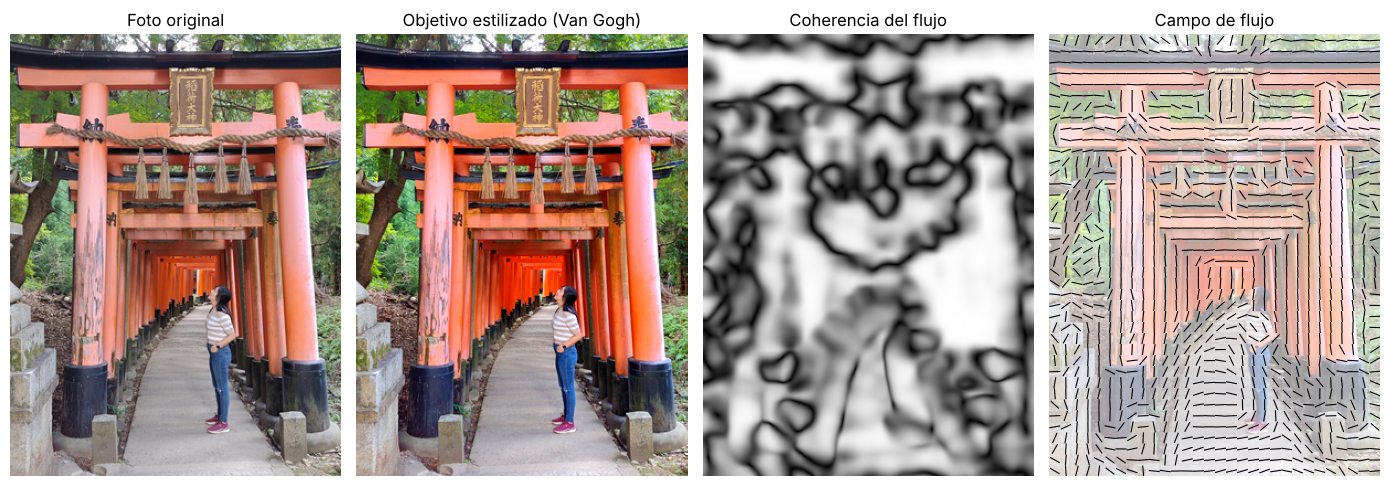

In [13]:
pintor_vg = Pintor(RUTA_IMAGEN, "vangogh", ANCHO, ESCALA_SALIDA, SEMILLA)
H, W = pintor_vg.objetivo.shape[:2]
fig, ax = plt.subplots(1, 4, figsize=(14, 5))
ax[0].imshow(pintor_vg.original); ax[0].set_title("Foto original")
ax[1].imshow(pintor_vg.objetivo.astype("uint8")); ax[1].set_title("Objetivo estilizado (Van Gogh)")
ax[2].imshow(pintor_vg.coherencia, cmap="gray"); ax[2].set_title("Coherencia del flujo")
ax[3].imshow(pintor_vg.objetivo.astype("uint8"), alpha=0.4); ax[3].set_title("Campo de flujo")
paso = max(6, W // 30)
for y in range(paso // 2, H, paso):
    for x in range(paso // 2, W, paso):
        a = pintor_vg.flujo[y, x]; d = 0.45 * paso
        ax[3].plot([x - d * np.cos(a), x + d * np.cos(a)], [y - d * np.sin(a), y + d * np.sin(a)], "k-", lw=0.8)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 13. Pinceladas aleatorias (idea original de Angie)
Antes de evolucionar, así se ven 400 pinceladas generadas por `Pincelada_Randomizer` con focos al azar. Esto equivale a la **población inicial** de cada etapa.

Ejemplo de pincelada (fenotipo):
[ tipo: line, centro: (155.1,377.0), size: 60.0, width: 21.7, angle: 173 grados, alpha: 0.94, color: (210, 185, 186) ]
Sus genes (genotipo): {'x': 0.519, 'y': 0.945, 'angulo': 0.959, 'largo': 0.813, 'grosor': 0.913, 'alpha': 0.725, 'r': 0.826, 'g': 0.729, 'b': 0.73, 'curvatura': 0.5}


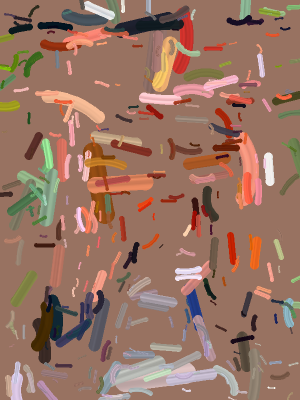

In [14]:
demo = ImagenEvolutiva(pintor_vg.objetivo, pintor_vg.estilo, escala_salida=1)
rng_demo = np.random.default_rng(1)
for i in range(400):
    L = largo_de_capa(i / 400, pintor_vg.estilo, W)
    foco = (rng_demo.uniform(0, W - 1), rng_demo.uniform(0, H - 1))
    genes = pintor_vg.randomizer.generate_Random_Pincelada(foco, L)
    if i == 0:
        genes_ejemplo = genes.copy()
    demo.add_Pincelada(Pincelada.from_Genes(genes, L, pintor_vg.estilo, H, W, semilla=i))
print("Ejemplo de pincelada (fenotipo):")
demo.lista_pinceladas[0].print()
print("Sus genes (genotipo):", {k: round(float(v), 3) for k, v in zip(NOMBRES_GENES, genes_ejemplo)})
display(miniatura(demo.generate_image(), 300))

## 14. Una etapa del AG por dentro
Se corre **una** etapa y se grafica el mejor fitness de cada generación. La línea punteada es el fitness del lienzo **sin** la pincelada nueva: el AG tiene que quedar por debajo de ella para que la pincelada se acepte.

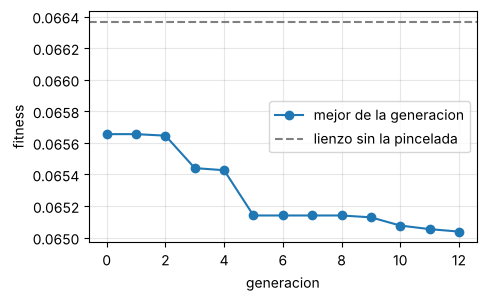

[ tipo: line, centro: (263.3,197.1), size: 66.8, width: 17.9, angle: 84 grados, alpha: 0.95, color: (250, 163, 150) ]


In [15]:
L0 = largo_de_capa(0, pintor_vg.estilo, W)
mejor, f_mejor = pintor_vg.ag.evolucionar_Etapa(L0)
plt.figure(figsize=(5, 3))
plt.plot(pintor_vg.ag.mejor_por_generacion, "o-", label="mejor de la generacion")
plt.axhline(pintor_vg.ag.fitness_Actual(), ls="--", c="gray", label="lienzo sin la pincelada")
plt.xlabel("generacion"); plt.ylabel("fitness"); plt.legend(); plt.grid(alpha=.3); plt.show()
for g in mejor:
    Pincelada.from_Genes(g, L0, pintor_vg.estilo, H, W).print()

## 15. Pintar estilo **Van Gogh**
Se muestran las capturas guardadas durante la evolución (25, 50, 100, … pinceladas).

In [16]:
import time
pintor_vg = Pintor(RUTA_IMAGEN, "vangogh", ANCHO, ESCALA_SALIDA, SEMILLA)   # empieza de cero
capturas_vg = []
t0 = time.time()
pintor_vg.pintar(PINCELADAS, os.path.join(CARPETA, "vangogh"),
                 al_capturar=lambda p, n: capturas_vg.append((n, miniatura(p.lienzo.generate_image(), 240))))
print(f"Tiempo: {time.time() - t0:.0f} s")
cols = 5; filas = (len(capturas_vg) + cols - 1) // cols
fig, ax = plt.subplots(filas, cols, figsize=(3 * cols, 4 * filas))
for a in ax.ravel(): a.axis("off")
for a, (n, im) in zip(ax.ravel(), capturas_vg):
    a.imshow(im); a.set_title(f"{n} pinceladas")
plt.tight_layout(); plt.show()

pinceladas=    25  etapa=    25  MSE=0.04866  PSNR=13.13 dB  cobertura=0.27  largo= 44.6px  rechazadas=0  t=1s


pinceladas=    50  etapa=    50  MSE=0.03745  PSNR=14.27 dB  cobertura=0.44  largo= 42.5px  rechazadas=0  t=2s


pinceladas=   100  etapa=   100  MSE=0.02857  PSNR=15.44 dB  cobertura=0.61  largo= 39.3px  rechazadas=0  t=4s


pinceladas=   200  etapa=   200  MSE=0.02172  PSNR=16.63 dB  cobertura=0.76  largo= 34.6px  rechazadas=0  t=8s


pinceladas=   400  etapa=   400  MSE=0.01651  PSNR=17.82 dB  cobertura=0.87  largo= 28.2px  rechazadas=0  t=14s


pinceladas=   800  etapa=   800  MSE=0.01224  PSNR=19.12 dB  cobertura=0.93  largo= 20.2px  rechazadas=0  t=25s


pinceladas=  1600  etapa=  1601  MSE=0.00897  PSNR=20.47 dB  cobertura=0.96  largo= 11.8px  rechazadas=1  t=45s


pinceladas=  3000  etapa=  3003  MSE=0.00645  PSNR=21.91 dB  cobertura=0.98  largo=  5.4px  rechazadas=3  t=76s


Tiempo: 77 s


{
 "estilo": "Van Gogh",
 "pinceladas": 3000,
 "etapas": 3003,
 "rechazadas": 3,
 "evaluaciones_fitness": 624624,
 "mse_normalizado_vs_objetivo": 0.006445162783044641,
 "psnr_db_vs_objetivo": 21.907661093601888,
 "psnr_db_vs_foto_original": 20.92092500172322,
 "ssim_vs_objetivo": 0.6507948151958937,
 "cobertura": 0.9775333333333334,
 "desalineacion_flujo": 0.01653154985035843,
 "tiempo_s": 75.89993834495544,
 "resolucion_trabajo": [
  300,
  400
 ],
 "resolucion_salida": [
  900,
  1200
 ]
}


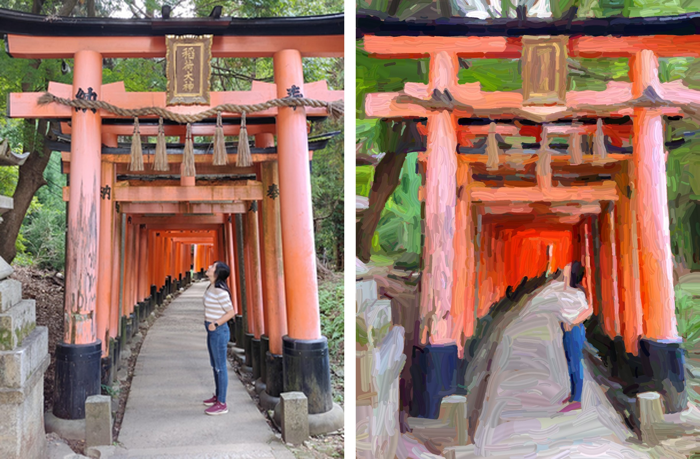

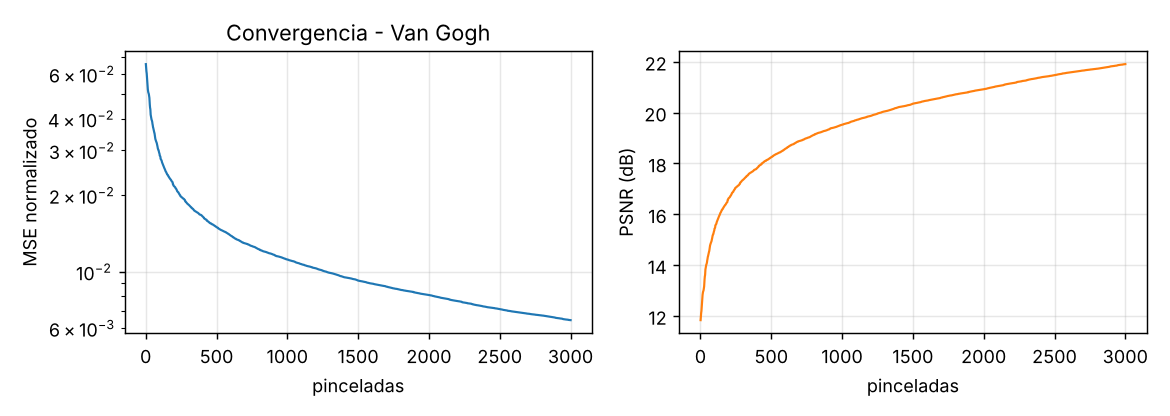

In [17]:
import json
print(json.dumps(json.load(open(os.path.join(CARPETA, "vangogh", "metricas.json"))), indent=1))
display(miniatura(Image.open(os.path.join(CARPETA, "vangogh", "comparacion.jpg")), 700))
display(Image.open(os.path.join(CARPETA, "vangogh", "convergencia.png")))

## 16. Pintar estilo **Monet**
Es el mismo algoritmo con otro diccionario de estilo: toques cortos y semitransparentes, un objetivo suavizado y sin término de flujo.

pinceladas=    25  etapa=    25  MSE=0.02913  PSNR=15.36 dB  cobertura=0.27  largo= 29.0px  rechazadas=0  t=1s


pinceladas=    50  etapa=    50  MSE=0.02188  PSNR=16.60 dB  cobertura=0.47  largo= 28.3px  rechazadas=0  t=2s


pinceladas=   100  etapa=   100  MSE=0.01497  PSNR=18.25 dB  cobertura=0.68  largo= 27.0px  rechazadas=0  t=3s


pinceladas=   200  etapa=   200  MSE=0.01001  PSNR=20.00 dB  cobertura=0.84  largo= 25.0px  rechazadas=0  t=6s


pinceladas=   400  etapa=   400  MSE=0.00677  PSNR=21.69 dB  cobertura=0.93  largo= 21.8px  rechazadas=0  t=12s


pinceladas=   800  etapa=   801  MSE=0.00452  PSNR=23.45 dB  cobertura=0.97  largo= 17.2px  rechazadas=1  t=23s


pinceladas=  1600  etapa=  1617  MSE=0.00288  PSNR=25.41 dB  cobertura=0.99  largo= 11.3px  rechazadas=17  t=43s


pinceladas=  3000  etapa=  3026  MSE=0.00179  PSNR=27.47 dB  cobertura=1.00  largo=  6.0px  rechazadas=26  t=75s


Tiempo: 77 s
{
 "estilo": "Monet",
 "pinceladas": 3000,
 "etapas": 3026,
 "rechazadas": 26,
 "evaluaciones_fitness": 629408,
 "mse_normalizado_vs_objetivo": 0.0017895455298629467,
 "psnr_db_vs_objetivo": 27.472572477536087,
 "psnr_db_vs_foto_original": 22.175635526955944,
 "ssim_vs_objetivo": 0.8041643362566688,
 "cobertura": 0.9950666666666667,
 "desalineacion_flujo": 0.14597561188325986,
 "tiempo_s": 74.77660036087036,
 "resolucion_trabajo": [
  300,
  400
 ],
 "resolucion_salida": [
  900,
  1200
 ]
}


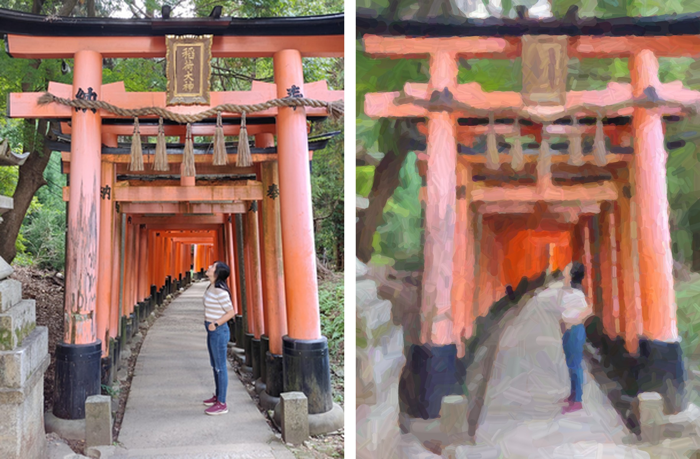

In [18]:
pintor_mo = Pintor(RUTA_IMAGEN, "monet", ANCHO, ESCALA_SALIDA, SEMILLA)
capturas_mo = []
t0 = time.time()
pintor_mo.pintar(PINCELADAS, os.path.join(CARPETA, "monet"),
                 al_capturar=lambda p, n: capturas_mo.append((n, miniatura(p.lienzo.generate_image(), 240))))
print(f"Tiempo: {time.time() - t0:.0f} s")
fig, ax = plt.subplots(filas, cols, figsize=(3 * cols, 4 * filas))
for a in ax.ravel(): a.axis("off")
for a, (n, im) in zip(ax.ravel(), capturas_mo):
    a.imshow(im); a.set_title(f"{n} pinceladas")
plt.tight_layout(); plt.show()
print(json.dumps(json.load(open(os.path.join(CARPETA, "monet", "metricas.json"))), indent=1))
display(miniatura(Image.open(os.path.join(CARPETA, "monet", "comparacion.jpg")), 700))

## 17. (Opcional) ¿El AG le gana a la búsqueda aleatoria?
Se compara con la misma cantidad de evaluaciones de fitness: el AG (16 individuos × 13 evaluaciones) contra 208 pinceladas aleatorias guiadas por etapa de las que se elige la mejor. Esta es la forma correcta de defender que la **evolución** (selección, cruza y mutación) aporta algo más allá de la buena inicialización. Pon `EJECUTAR = True` para correrlo (~3 min).

In [19]:
EJECUTAR = False
if EJECUTAR:
    curvas = {}
    for nombre, aleatoria in (("AG", False), ("Busqueda aleatoria", True)):
        p = Pintor(RUTA_IMAGEN, "libre", 300, 1, SEMILLA, busqueda_aleatoria=aleatoria)
        p.pintar(2000, None, verbose=False)
        curvas[nombre] = p.historial
        print(f"{nombre:20s} MSE final = {p.lienzo.mse():.5f}  evaluaciones = {p.ag.evaluaciones}")
    plt.figure(figsize=(5, 3))
    for nombre, h in curvas.items():
        plt.plot([x["pinceladas"] for x in h], [x["mse"] for x in h], label=nombre)
    plt.yscale("log"); plt.xlabel("pinceladas"); plt.ylabel("MSE"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 18. Conclusiones rápidas
- El AG por etapas reproduce la imagen con pinceladas visibles. El **estilo** sale de tres fuentes: la forma de las pinceladas, el objetivo estilizado y el término de flujo en el fitness.
- Con el mismo número de evaluaciones, el AG obtiene menor error que la búsqueda aleatoria guiada (ver `resultados/experimentos`).
- Más pinceladas y una resolución mayor mejoran la fidelidad, pero el tiempo crece casi linealmente con el número de pinceladas.
- Ver `DOCUMENTACION.md` en la raíz del repositorio para limitaciones, alcances y cómo defender el trabajo.